# B2 — Which signs open and close inscriptions?

**Task:** count the first and last signs of each inscription, make one comparison
chart, and check that the jar sign (Wells 740) is strongly associated with endings.
This standalone notebook runs without B1 files, so B2 can be reviewed independently.
Select the project's `.venv/bin/python` kernel and run all cells top to bottom.

Source: the same **1,837 filtered unique ICIT inscriptions, using Wells IDs**.
`load_sequences()` supplies the project's reading order; no extra reversal is
needed. We do not mix these IDs with the Mahadevan/IM77 snapshot, edit raw data,
or infer what a sign means. No training, random sampling or data split is involved.

## 1. Endpoint counting by hand

```text
[151, 105, 151, 740] → start 151, end 740
[151, 740]           → start 151, end 740
[151, 151, 740]      → start 151, end 740
```

Each inscription gives one vote for its start and one for its end, regardless
of its length. This invented corpus has start counts `{151: 3}`, end counts
`{740: 3}`. Sign 105 is present but never an endpoint: it must still appear
in the full table with zero endpoint counts.

Python indexing starts at zero: `sequence[0]` is the first element;
`sequence[-1]` is the last. A sign occurring repeatedly inside a sequence
contributes to its overall frequency, but only its endpoint positions count here.

In [1]:
import sys
import json
import hashlib
import math
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from indus.data import load_sequences, REPO_ROOT, SEQUENCES_FILE, wells_to_mahadevan
from indus.endpoints import count_endpoints, endpoint_table

print("Python interpreter:", sys.executable)
toy = [[151, 105, 151, 740], [151, 740], [151, 151, 740]]
toy_starts, toy_ends = count_endpoints(toy)
assert toy_starts == {151: 3}
assert toy_ends == {740: 3}
toy_table = endpoint_table(toy).set_index("wells_id")
assert toy_table.loc[151, "total_count"] == 5
assert toy_table.loc[151, "start_probability"] == 1
assert toy_table.loc[151, "start_share_of_sign"] == 3 / 5
assert toy_table.loc[740, "end_probability"] == 1
assert toy_table.loc[740, "end_share_of_sign"] == 1
assert toy_table.loc[105, "start_count"] == 0
assert toy_table.loc[105, "end_count"] == 0

# A second hand-counted corpus tests repeats and nonuniform endpoints.
mixed = [[10, 20, 10], [20, 30], [10]]
assert count_endpoints(mixed) == ({10: 2, 20: 1}, {10: 2, 30: 1})
mixed_table = endpoint_table(mixed).set_index("wells_id")
assert mixed_table.loc[10, "total_count"] == 3
assert mixed_table.loc[10, "end_share_of_sign"] == 2 / 3
assert count_endpoints([[10]]) == ({10: 1}, {10: 1})
for function in (count_endpoints, endpoint_table):
    for invalid in ([], [[]], [[10], []]):
        try:
            function(invalid)
        except ValueError:
            pass
        else:
            raise AssertionError("Empty corpus or sequence should be rejected")
print("Hand counts, zero endpoints, repeats, one-sign and invalid-input checks passed.")
display(toy_table)

Python interpreter: /home/devambhavsar/ML/AI_Project/.venv/bin/python
Hand counts, zero endpoints, repeats, one-sign and invalid-input checks passed.


,total_count,start_count,end_count,start_probability,end_probability,start_share_of_sign,end_share_of_sign
wells_id,,,,,,,
105,1,0,0,0.0,0.0,0.0,0.0
151,5,3,0,1.0,0.0,0.6,0.0
740,3,0,3,0.0,1.0,0.0,1.0


### Understand the reusable Python

Open `src/indus/endpoints.py`. `count_endpoints()` creates two `Counter` counting
tables. A `for` loop visits every sequence, adding one to its first sign in the
start table and one to its last sign in the end table. `return starts, ends`
returns two answers; `starts, ends = ...` assigns them to two names.

`endpoint_table()` additionally counts every occurrence with `Counter.update()`.
This includes repeats. It makes one row per observed sign type, including types
seen only inside texts, and returns a pandas `DataFrame` (a table with named columns).
`sorted(totals)` sorts IDs to make row order deterministic.

A one-sign sequence has the same start and end. The function handles that
correctly even though our ICIT corpus excludes single-sign texts.
Empty sequences have no endpoints, so we reject them instead of silently
changing the denominator. `assert` stops execution if an expected answer fails.

## 2. Load the corpus and inspect real examples

The loader already handles reading order. The first sign is the first read;
the last is the last read. The source has no object IDs, so the example index
below is a Python row position, **not an IM77 text number**.

Corpus limitations from `data/README.md`: unique texts only, excluding damaged,
multiline and single-sign inscriptions. Results describe this subset, not every
Indus object. The existing orientation convention is an input to B2.

In [2]:
sequences = load_sequences()
starts, ends = count_endpoints(sequences)
table = endpoint_table(sequences)
n_sequences = len(sequences)
assert n_sequences == 1837
assert len(table) == 568
assert int(table["total_count"].sum()) == 8359
examples = pd.DataFrame([
    {"row_index": i, "reading_order": sequence,
     "start": sequence[0], "end": sequence[-1]}
    for i, sequence in enumerate(sequences[:5])
])
display(examples)
print("Sequences:", n_sequences)
print("Types appearing at starts:", len(starts))
print("Types appearing at ends:", len(ends))

,row_index,reading_order,start,end
0,0,"[142, 1]",142,1
1,1,"[33, 812, 125, 354, 304, 1]",33,1
2,2,"[351, 368, 1]",351,1
3,3,"[767, 368, 1]",767,1
4,4,"[371, 255, 861, 368, 1]",371,1


Sequences: 1837
Types appearing at starts: 373
Types appearing at ends: 199


## 3. Name the denominator before interpreting a fraction

For a sign `s`, let `S(s)` count starts, `E(s)` count ends and `C(s)` count all
its occurrences. Let `T` be the number of sequences (1,837).

| Table column | Formula | Question answered |
|---|---|---|
| `start_probability` | `S(s) / T` | What fraction of texts starts with s? |
| `end_probability` | `E(s) / T` | What fraction of texts ends with s? |
| `start_share_of_sign` | `S(s) / C(s)` | What fraction of s's occurrences occupies a start? |
| `end_share_of_sign` | `E(s) / C(s)` | What fraction of s's occurrences occupies an end? |

Multiply a fraction by 100 to express it as a percentage. These are observed
corpus proportions, not probabilities learned by a trained model.
The two probability columns each sum to 1 across signs. The share-of-sign
columns do not: each row has its own denominator.

In the toy corpus, every text starts with 151, but only 3 of its 5 occurrences
are starts. That gives 100% for `start_probability` and 60% for `start_share_of_sign`.

In [3]:
# Break equal-count ties by ascending Wells ID.
top_starts = table.sort_values(["start_count", "wells_id"], ascending=[False, True]).head(10)
top_ends = table.sort_values(["end_count", "wells_id"], ascending=[False, True]).head(10)
print("Ten most frequent opening signs (fractions use all 1,837 sequences):")
display(top_starts[["wells_id", "start_count", "start_probability", "start_share_of_sign"]])
print("Ten most frequent closing signs:")
display(top_ends[["wells_id", "end_count", "end_probability", "end_share_of_sign"]])

jar = table.set_index("wells_id").loc[740]
jar_total = int(jar["total_count"])
jar_start = int(jar["start_count"])
jar_end = int(jar["end_count"])
jar_ratio = jar_end / jar_start if jar_start else None
assert wells_to_mahadevan()[740] == {342}
assert int(top_ends.iloc[0]["wells_id"]) == 740
assert jar_end > 10 * jar_start
print(f"Jar (Wells 740 / Mahadevan 342): {jar_total} total tokens; "
      f"{jar_start} starts; {jar_end} ends.")
print(f"Texts starting with jar: {jar_start / n_sequences:.2%}")
print(f"Texts ending with jar: {jar_end / n_sequences:.2%}")
print(f"Jar tokens at ends: {jar_end / jar_total:.2%}")
print("End/start count ratio:", f"{jar_ratio:.2f}" if jar_ratio is not None else "undefined: no starts")

Ten most frequent opening signs (fractions use all 1,837 sequences):


,wells_id,start_count,start_probability,start_share_of_sign
488,820,109,0.059336,0.751724
486,817,106,0.057703,0.913793
515,861,102,0.055525,0.698630
553,920,55,0.029940,0.617978
20,32,50,0.027218,0.230415
152,235,49,0.026674,0.368421
19,31,42,0.022863,0.352941
154,240,39,0.021230,0.216667
2,3,33,0.017964,0.326733
406,692,31,0.016875,0.738095


Ten most frequent closing signs:


,wells_id,end_count,end_probability,end_share_of_sign
436,740,647,0.352205,0.717295
258,400,187,0.101796,0.894737
329,520,127,0.069134,0.824675
254,390,71,0.038650,0.461039
55,90,64,0.034839,0.752941
99,151,45,0.024496,0.865385
333,527,38,0.020686,0.863636
262,407,34,0.018508,0.666667
260,405,29,0.015787,0.568627
411,700,29,0.015787,0.500000


Jar (Wells 740 / Mahadevan 342): 902 total tokens; 3 starts; 647 ends.
Texts starting with jar: 0.16%
Texts ending with jar: 35.22%
Jar tokens at ends: 71.73%
End/start count ratio: 215.67


## 4. One chart comparing the same signs at both endpoints

Select the union of the five most frequent opening and five most frequent
closing signs. For each selected ID, show **both** percentages side by side.
Order the selected IDs by their larger endpoint count (ties by smaller ID).
This avoids comparing bars for different IDs as if they were the same sign.

The horizontal axis is the percentage of all 1,837 texts. The selected bars
show a subset, so they need not add to 100%. The complete exported table
includes all 568 observed types. The jar sign is explicitly labelled.

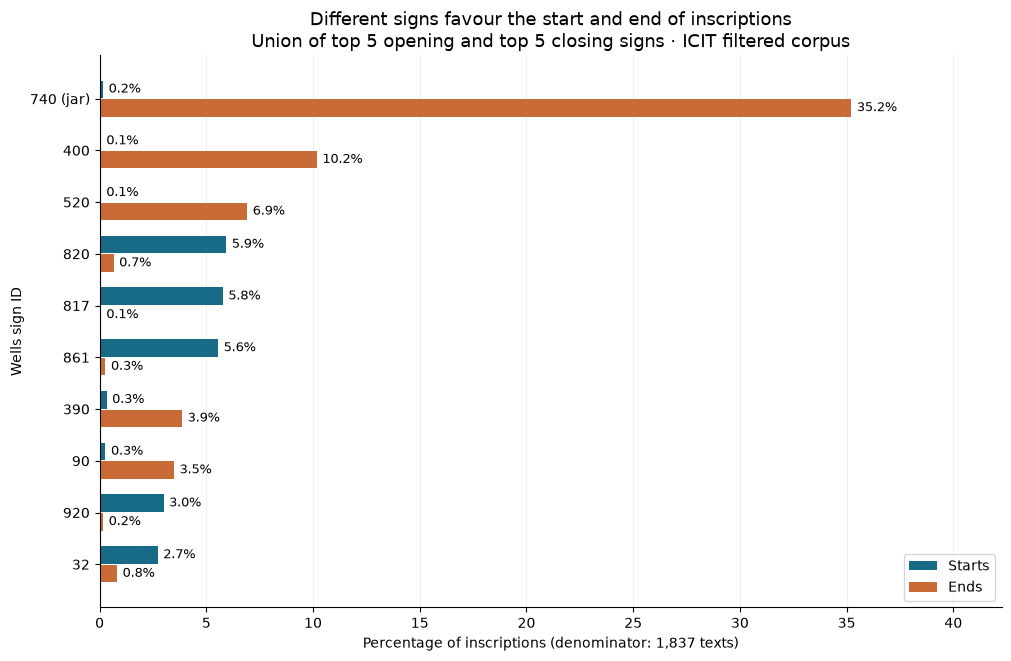

In [4]:
selected_ids = set(top_starts.head(5)["wells_id"]) | set(top_ends.head(5)["wells_id"])
chart = table[table["wells_id"].isin(selected_ids)].copy()
chart["largest_endpoint_count"] = chart[["start_count", "end_count"]].max(axis=1)
chart = chart.sort_values(["largest_endpoint_count", "wells_id"], ascending=[False, True])
positions = list(range(len(chart)))
labels = [f"{sign} (jar)" if sign == 740 else str(sign) for sign in chart["wells_id"]]

fig, ax = plt.subplots(figsize=(10, 6.5), layout="constrained")
start_bars = ax.barh([y - 0.18 for y in positions], chart["start_probability"] * 100,
                     height=0.34, color="#176B87", label="Starts")
end_bars = ax.barh([y + 0.18 for y in positions], chart["end_probability"] * 100,
                   height=0.34, color="#C86B37", label="Ends")
ax.bar_label(start_bars, fmt="%.1f%%", padding=4, fontsize=9)
ax.bar_label(end_bars, fmt="%.1f%%", padding=4, fontsize=9)
ax.set_yticks(positions, labels)
ax.invert_yaxis()
ax.set_xlabel("Percentage of inscriptions (denominator: 1,837 texts)")
ax.set_ylabel("Wells sign ID")
ax.set_title("Different signs favour the start and end of inscriptions\n"
             "Union of top 5 opening and top 5 closing signs · ICIT filtered corpus", fontsize=13)
ax.set_xlim(0, max(chart["start_probability"].max(), chart["end_probability"].max()) * 120)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="lower right")
figures = REPO_ROOT / "reports/figures"
figures.mkdir(parents=True, exist_ok=True)
fig.savefig(figures / "b2_endpoints.png", dpi=180)
plt.show()
plt.close(fig)

## 5. Check the result independently

1. Every sequence must contribute exactly one start and one end.
2. Endpoint probabilities must each sum to one (with floating-point tolerance).
3. No endpoint count may exceed that sign's total occurrence count.
4. Separate dictionaries, incremented from the loaded sequences, must agree
   with every count in the table, including zeros for interior-only types.
5. Reversing every sequence must exchange start/end results exactly.
6. The jar sign must pass the existing direction sanity expectation.

Reversal is a test here, not the order used for reporting. B2 confirms a
known endpoint pattern under the loader convention; it does not independently
establish the script's direction or decipher the signs.

In [5]:
assert sum(starts.values()) == n_sequences
assert sum(ends.values()) == n_sequences
assert math.isclose(table["start_probability"].sum(), 1, abs_tol=1e-12)
assert math.isclose(table["end_probability"].sum(), 1, abs_tol=1e-12)
assert (table["start_count"] <= table["total_count"]).all()
assert (table["end_count"] <= table["total_count"]).all()
for column in ("start_probability", "end_probability", "start_share_of_sign", "end_share_of_sign"):
    assert table[column].between(0, 1).all()

independent_starts, independent_ends, independent_totals = {}, {}, {}
for sequence in sequences:
    first, last = sequence[0], sequence[-1]
    independent_starts[first] = independent_starts.get(first, 0) + 1
    independent_ends[last] = independent_ends.get(last, 0) + 1
    for sign in sequence:
        independent_totals[sign] = independent_totals.get(sign, 0) + 1
assert dict(starts) == independent_starts
assert dict(ends) == independent_ends
for row in table.itertuples(index=False):
    assert row.total_count == independent_totals[row.wells_id]
    assert row.start_count == independent_starts.get(row.wells_id, 0)
    assert row.end_count == independent_ends.get(row.wells_id, 0)

reversed_sequences = [sequence[::-1] for sequence in sequences]
reversed_starts, reversed_ends = count_endpoints(reversed_sequences)
assert reversed_starts == ends and reversed_ends == starts
reversed_table = endpoint_table(reversed_sequences)
assert reversed_table["wells_id"].equals(table["wells_id"])
assert reversed_table["start_probability"].equals(table["end_probability"])
assert reversed_table["end_probability"].equals(table["start_probability"])
assert reversed_table["start_share_of_sign"].equals(table["end_share_of_sign"])
assert reversed_table["end_share_of_sign"].equals(table["start_share_of_sign"])
print("All real-corpus conservation, independent counting, probability and reversal checks passed.")

All real-corpus conservation, independent counting, probability and reversal checks passed.


## 6. Export reproducible results

Regenerable files go to `data/processed/b2/` (ignored by Git): the complete
endpoint table, two top-ten tables, and a source/checksum summary. The report
figure stays in `reports/figures/`. A SHA-256 identifies the source file's bytes;
it does not prove the source transcription is correct.

The check below reads the full CSV back and compares every column against the
in-memory table, allowing the tiny floating-point changes from CSV formatting.

In [6]:
processed = REPO_ROOT / "data/processed/b2"
processed.mkdir(parents=True, exist_ok=True)
table.to_csv(processed / "endpoint_counts.csv", index=False)
top_starts.to_csv(processed / "top_starts.csv", index=False)
top_ends.to_csv(processed / "top_ends.csv", index=False)
saved_summary = {
    "dataset": "ICIT 1837 filtered unique inscriptions", "numbering": "Wells",
    "order": "reading", "source": str(SEQUENCES_FILE.relative_to(REPO_ROOT)),
    "source_sha256": hashlib.sha256(SEQUENCES_FILE.read_bytes()).hexdigest(),
    "n_sequences": n_sequences, "n_tokens": int(table["total_count"].sum()),
    "n_types": len(table), "n_start_types": len(starts), "n_end_types": len(ends),
    "jar_wells_id": 740, "jar_mahadevan_id": 342, "jar_total_count": jar_total,
    "jar_start_count": jar_start, "jar_end_count": jar_end,
    "jar_start_probability": jar_start / n_sequences,
    "jar_end_probability": jar_end / n_sequences,
    "jar_end_share_of_sign": jar_end / jar_total,
    "jar_end_start_ratio": jar_ratio,
    "chart_selected_wells_ids": [int(sign) for sign in chart["wells_id"]],
}
(processed / "summary.json").write_text(json.dumps(saved_summary, indent=2) + "\n")
pd.testing.assert_frame_equal(pd.read_csv(processed / "endpoint_counts.csv"), table,
                             check_exact=False, rtol=1e-12, atol=1e-12)
print("Saved:", figures / "b2_endpoints.png")
print("Saved tables and provenance:", processed)
print(json.dumps(saved_summary, indent=2))

Saved: /home/devambhavsar/ML/AI_Project/reports/figures/b2_endpoints.png
Saved tables and provenance: /home/devambhavsar/ML/AI_Project/data/processed/b2
{
  "dataset": "ICIT 1837 filtered unique inscriptions",
  "numbering": "Wells",
  "order": "reading",
  "source": "data/raw/icit_1837_sequences.csv",
  "source_sha256": "140a61e57dfaccd15867d9a00141f180a38080141b0ad18bb4262c782024f186",
  "n_sequences": 1837,
  "n_tokens": 8359,
  "n_types": 568,
  "n_start_types": 373,
  "n_end_types": 199,
  "jar_wells_id": 740,
  "jar_mahadevan_id": 342,
  "jar_total_count": 902,
  "jar_start_count": 3,
  "jar_end_count": 647,
  "jar_start_probability": 0.001633097441480675,
  "jar_end_probability": 0.35220468154599893,
  "jar_end_share_of_sign": 0.7172949002217295,
  "jar_end_start_ratio": 215.66666666666666,
  "chart_selected_wells_ids": [
    740,
    400,
    520,
    820,
    817,
    861,
    390,
    90,
    920,
    32
  ]
}


## 7. Interpretation and limits

The jar sign's end count, text-ending percentage and within-sign ending share
above describe different aspects of its strong association with final positions.
This does not identify its meaning, prove a grammatical role, or establish
direction without the loader's convention. Corpus filtering and deduplication
also limit generalisation to all archaeological objects.

These checks establish correct counting and orientation consistency for the
loaded data, not an independent audit of every original transcription.
The existing repository test suite is run separately with `python -m pytest`;
these new B2-specific checks live in this executable notebook.

**Explain it back:** Why are both endpoint totals 1,837? Why isn't the denominator
8,359 for the chart? How can every toy inscription start with 151 while only
60% of its tokens are starts? What changes if you reverse the sequences?

References: `docs/TASKS.md` (B2), `data/README.md` (source/limitations),
`src/indus/data.py` (orientation), and `tests/test_data.py` (jar-sign expectation).